In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/healthcare_preprocessed (1).csv")

In [ ]:
df.head()

,Name,Age,Gender,Blood_Type,Medical_Condition,Admission_Date,Doctor,Hospital,Insurance_Provider,Billing_Amount,Room Number,Admission_Type,Discharge_Date,Medication,Test_Results,Length_of_Stay,Age_Group,Admission_Urgency
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2,19-30,Urgent
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,61-75,Emergency
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15,76+,Emergency
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,19-30,Elective
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20,31-45,Urgent


In [ ]:
print(df.shape[0])
print(df.shape[1])

54966
18


In [ ]:
print(df.columns.tolist())

['Name', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition', 'Admission_Date', 'Doctor', 'Hospital', 'Insurance_Provider', 'Billing_Amount', 'Room Number', 'Admission_Type', 'Discharge_Date', 'Medication', 'Test_Results', 'Length_of_Stay', 'Age_Group', 'Admission_Urgency']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54966 entries, 0 to 54965
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                54966 non-null  object 
 1   Age                 54966 non-null  int64  
 2   Gender              54966 non-null  object 
 3   Blood_Type          54966 non-null  object 
 4   Medical_Condition   54966 non-null  object 
 5   Admission_Date      54966 non-null  object 
 6   Doctor              54966 non-null  object 
 7   Hospital            54966 non-null  object 
 8   Insurance_Provider  54966 non-null  object 
 9   Billing_Amount      54966 non-null  float64
 10  Room Number         54966 non-null  int64  
 11  Admission_Type      54966 non-null  object 
 12  Discharge_Date      54966 non-null  object 
 13  Medication          54966 non-null  object 
 14  Test_Results        54966 non-null  object 
 15  Length_of_Stay      54966 non-null  int64  
 16  Age_

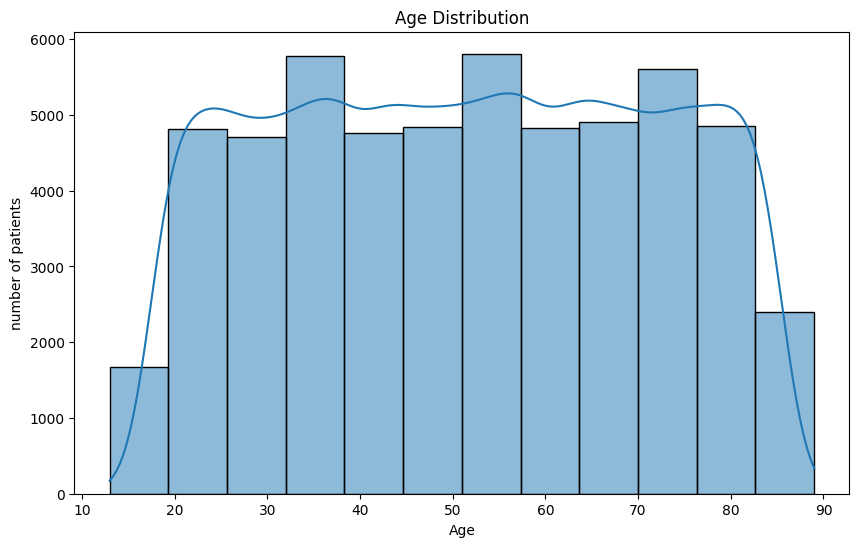

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,
            x="Age",
            bins=12,
            kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("number of patients")
plt.show()


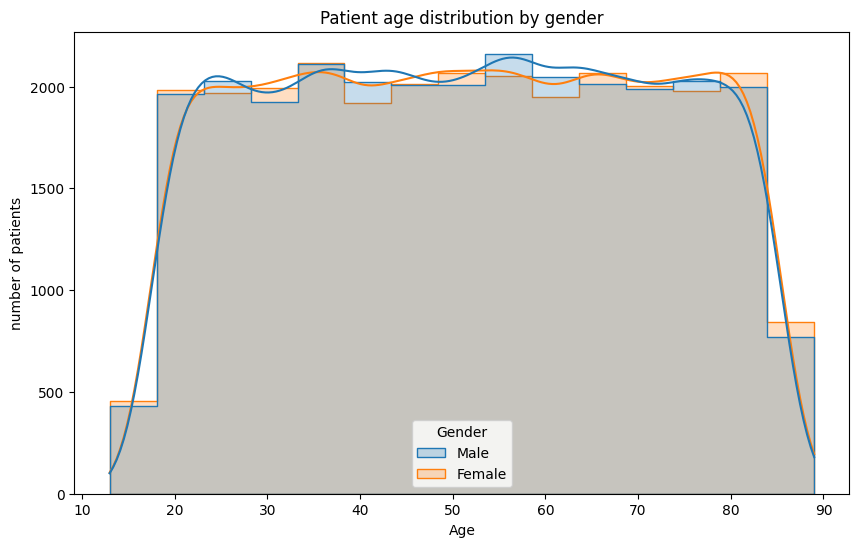

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,
            x="Age",
            hue="Gender",
            bins=15,
            kde=True,
             element="step"
             )
plt.title("Patient age distribution by gender")
plt.xlabel("Age")
plt.ylabel("number of patients")
plt.show()

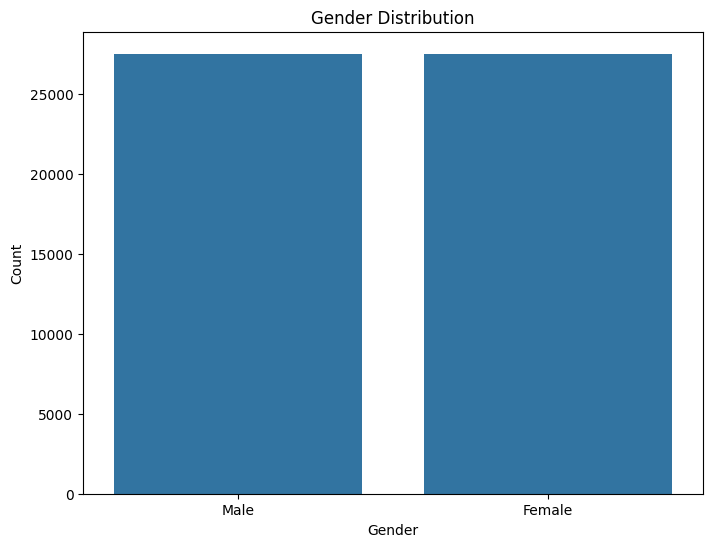

In [ ]:
gender_counts = df['Gender'].value_counts()
plt.figure(figsize=(8, 6))
sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values

)

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

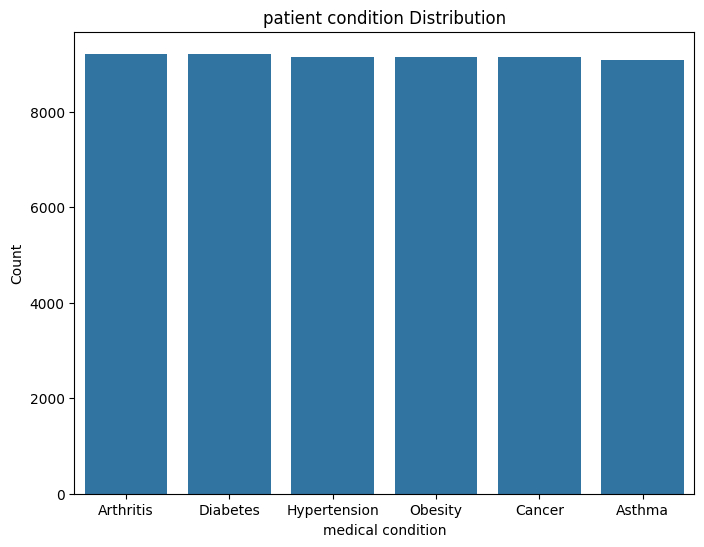

In [ ]:
condition_counts = df['Medical_Condition'].value_counts()
plt.figure(figsize=(8, 6))
sns.barplot(
    x=condition_counts.index,
    y=condition_counts.values

)

plt.title('patient condition Distribution')
plt.xlabel('medical condition')
plt.ylabel('Count')
plt.show()

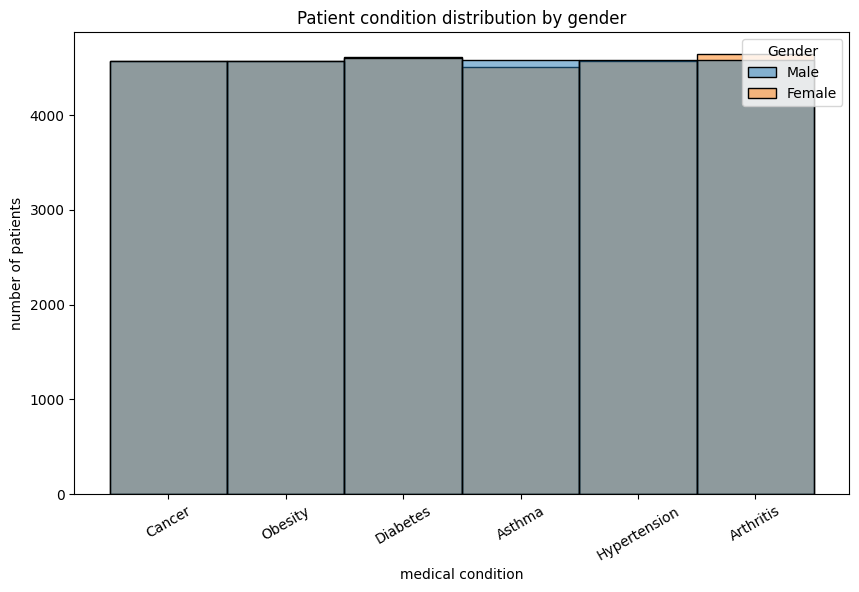

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,
            x="Medical_Condition",
            hue="Gender"

             )
plt.title("Patient condition distribution by gender")
plt.xlabel("medical condition")
plt.ylabel("number of patients")

plt.xticks(rotation=30)
plt.show()

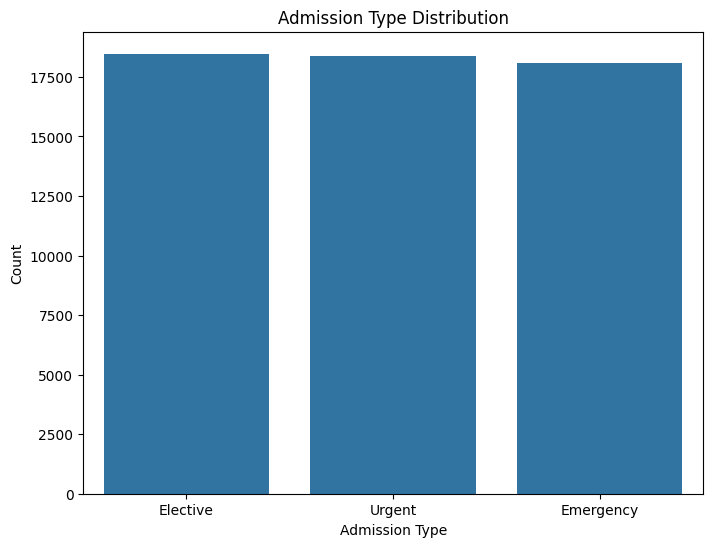

In [ ]:
admission_counts = df['Admission_Type'].value_counts()
plt.figure(figsize=(8, 6))
sns.barplot(
    x=admission_counts.index,
    y=admission_counts.values

)

plt.title('Admission Type Distribution')
plt.xlabel('Admission Type')
plt.ylabel('Count')
plt.show()

In [ ]:
admission_condition=pd.crosstab(df["Medical_Condition"],df["Admission_Type"])
print(admission_condition)

Admission_Type     Elective  Emergency  Urgent
Medical_Condition                             
Arthritis              3062       3073    3083
Asthma                 3069       2978    3048
Cancer                 3114       2988    3038
Diabetes               3031       2988    3197
Hypertension           3182       2975    2994
Obesity                3015       3100    3031


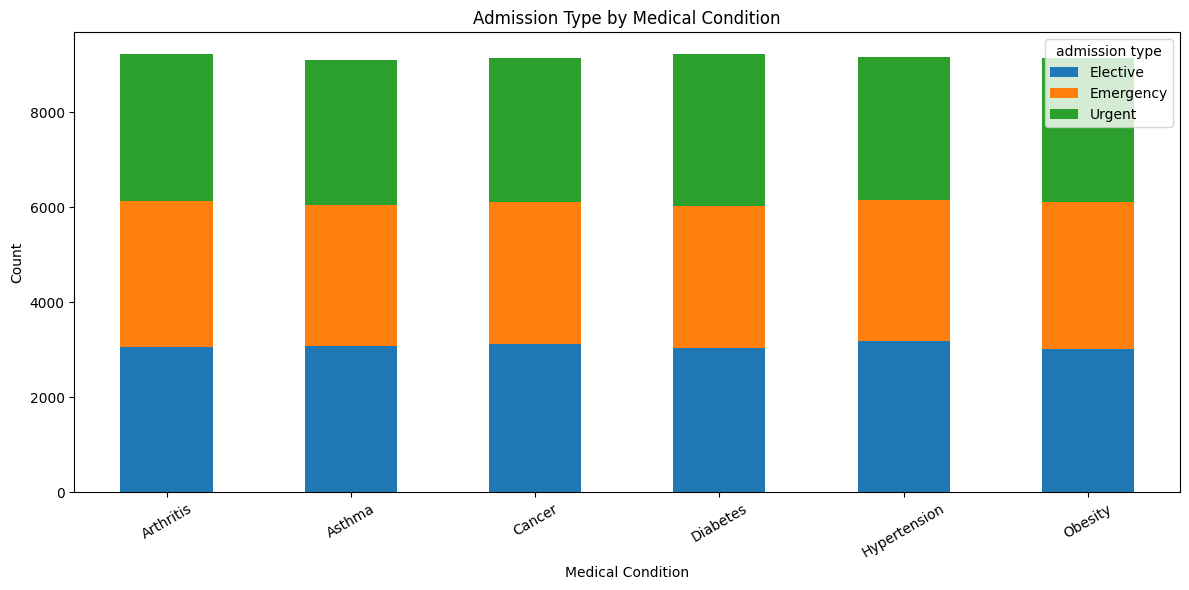

In [ ]:
admission_condition.plot(kind="bar",figsize=(12,6),stacked=True)
plt.title("Admission Type by Medical Condition")
plt.xlabel("Medical Condition")
plt.legend(title="admission type")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

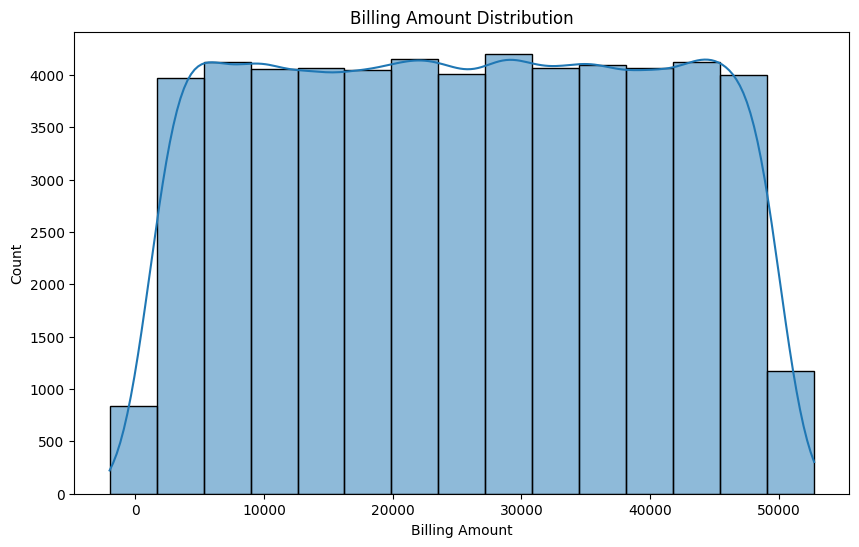

In [ ]:
 plt.figure(figsize=(10,6))
 sns.histplot(
     data=df,
     x="Billing_Amount",
     bins=15,
     kde=True
 )
 plt.title("Billing Amount Distribution")
 plt.xlabel("Billing Amount")
 plt.ylabel("Count")
 plt.show()

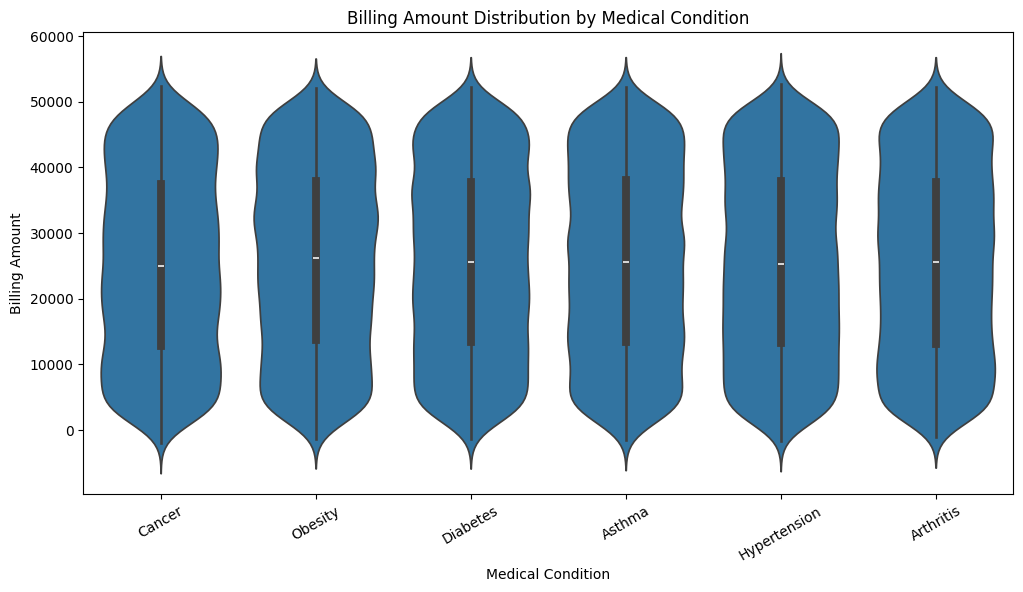

In [ ]:
plt.figure(figsize=(12,6))
sns.violinplot(data=df,x="Medical_Condition",y="Billing_Amount")
plt.title("Billing Amount Distribution by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Billing Amount")
plt.xticks(rotation=30)
plt.show()

In [ ]:
avg_condition_billing=(df.groupby("Medical_Condition")["Billing_Amount"].mean().sort_values(ascending=False))
print(avg_condition_billing)

Medical_Condition
Obesity         25804.361902
Diabetes        25660.478635
Asthma          25633.461696
Arthritis       25511.783246
Hypertension    25503.058720
Cancer          25152.322947
Name: Billing_Amount, dtype: float64


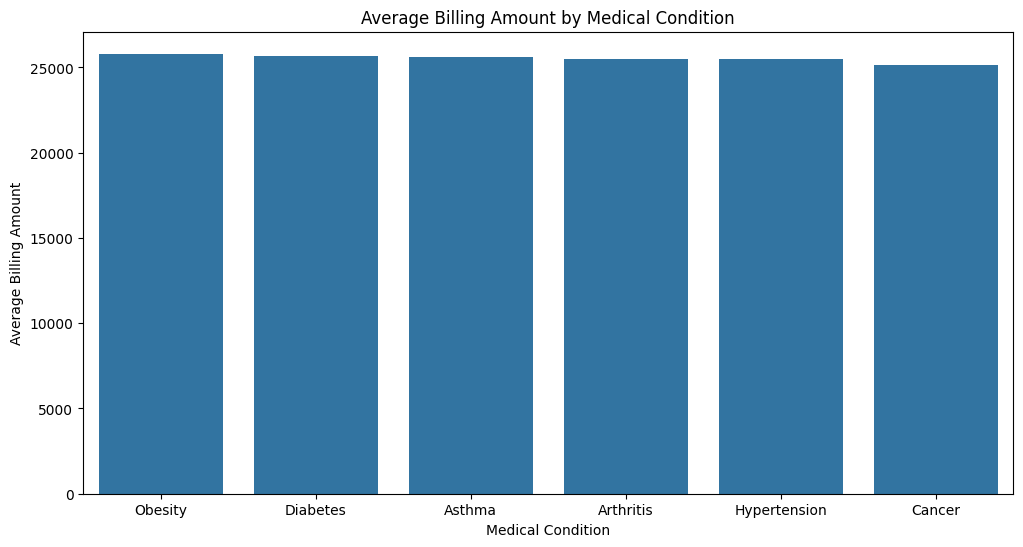

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=avg_condition_billing.index,
            y=avg_condition_billing.values)
plt.title("Average Billing Amount by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Average Billing Amount")
plt.show()

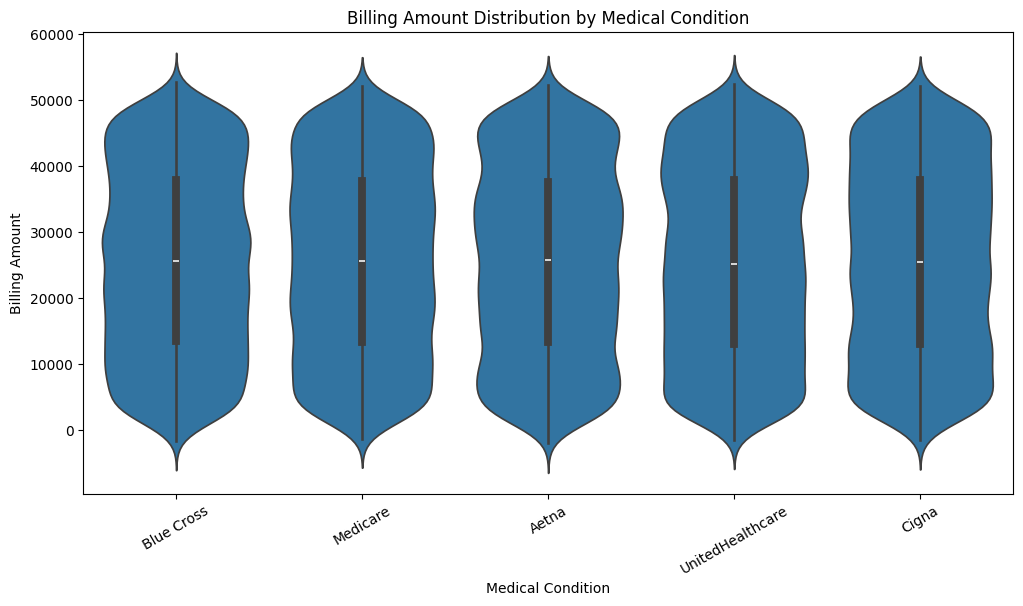

In [ ]:
plt.figure(figsize=(12,6))
sns.violinplot(data=df,x="Insurance_Provider",y="Billing_Amount")
plt.title("Billing Amount Distribution by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Billing Amount")
plt.xticks(rotation=30)
plt.show()

In [ ]:
Insurance_billing=(df.groupby("Insurance_Provider")["Billing_Amount"].mean().sort_values(ascending=False))
print(Insurance_billing)

Insurance_Provider
Medicare            25628.320208
Blue Cross          25603.460603
Aetna               25549.689648
Cigna               25525.998670
UnitedHealthcare    25414.506208
Name: Billing_Amount, dtype: float64


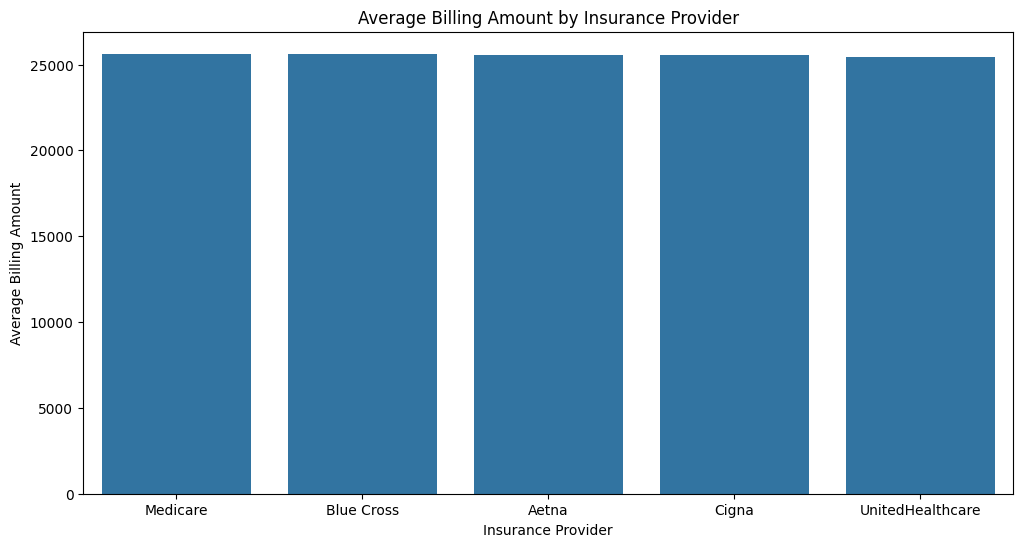

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=Insurance_billing.index,
            y=Insurance_billing.values)
plt.title("Average Billing Amount by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Average Billing Amount")
plt.show()

In [ ]:
insurance_biling=(df.groupby("Insurance_Provider")["Billing_Amount"].mean().sort_values(ascending=False))

In [ ]:
df["Admission_Date"]=pd.to_datetime(df["Admission_Date"])
df["Admission_Month"]=(df["Admission_Date"].dt.to_period("M"))

In [ ]:
monthly_billing=df.groupby("Admission_Month")["Billing_Amount"].mean()